# Do single-cell foundation models annotate diseased lung cells better?

Reference: **HLCA core** (healthy lung, CELLxGENE), stratified subsample. Query: **Melms et al. 2021** COVID-19 lung
(7 control + 20 COVID donors, snRNA-seq). Every method uses the same reference cells and is scored against the
query authors' labels, collapsed to coarse lineages by `label_map.csv` (query truth from the authors' `cell_type_intermediate`).

| Method | How it labels the query |
|---|---|
| PCA | 50 PCs fit on reference HVGs, kNN |
| CellTypist | logistic regression trained on the reference |
| scVI | scArches surgery, kNN on the latent space |
| scANVI | scArches surgery, own classifier (native) and kNN |
| Geneformer | zero-shot V2-104M embedding, kNN |
| scGPT | zero-shot whole-human embedding, kNN |

In [1]:
from pathlib import Path
import anndata as ad, numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import mannwhitneyu
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# Gold Tangerine (BERU Color-Schemes)
GOLD, TANGERINE, SILVER, CHARCOAL, DOVE, IVORY = "#f9d84b", "#fe5416", "#d9d9d9", "#28283d", "#b7b7b9", "#fffbeb"
COND = {"normal": CHARCOAL, "COVID-19": TANGERINE}
CMAP = LinearSegmentedColormap.from_list("gt", [IVORY, GOLD, TANGERINE])
sc.set_figure_params(dpi=90, frameon=False)
Path("figures").mkdir(exist_ok=True)

ref, qry = ad.read_h5ad("data/ref.h5ad"), ad.read_h5ad("data/query.h5ad")
for a in (ref, qry):
    a.layers["counts"] = a.X.copy()
    sc.pp.normalize_total(a, target_sum=1e4); sc.pp.log1p(a)
    a.var_names = a.var.feature_name.astype(str).values  # symbols for plotting
    a.var_names_make_unique()
nr, nq = ref.n_obs, qry.n_obs
truth, cond = qry.obs.coarse.astype(str), qry.obs.disease.astype(str)
print(nr, "reference cells,", nq, "query cells")
print(cond.value_counts().to_string())

emb = {m: np.load(f"results/emb_{m}.npy") for m in ["pca", "scvi", "scanvi", "geneformer", "scgpt"]
       if Path(f"results/emb_{m}.npy").exists()}
for m, e in emb.items():
    assert len(e) == nr + nq, m
print({m: e.shape[1] for m, e in emb.items()})

96364 reference cells, 116313 query cells
disease
COVID-19    79636
normal      36677


{'pca': 50, 'scvi': 30, 'scanvi': 30, 'geneformer': 768, 'scgpt': 512}


## 1. Sanity check: can each embedding separate reference cell types?
kNN trained on 80% of the reference, scored on the other 20%.

In [2]:
tr, te = train_test_split(np.arange(nr), test_size=0.2, stratify=ref.obs.coarse, random_state=0)
y = ref.obs.coarse.astype(str).values
print(pd.Series({m: f1_score(y[te], KNeighborsClassifier(15, n_jobs=-1).fit(e[tr], y[tr]).predict(e[te]), average="macro")
                 for m, e in emb.items()}, name="ref macro-F1").round(3).to_string())

pca           0.962
scvi          0.968
scanvi        0.979
geneformer    0.965
scgpt         0.962


## 2. Label transfer to the patient cells

In [3]:
def knn(e, k=15):
    clf = KNeighborsClassifier(k, n_jobs=-1).fit(e[:nr], y)
    p = clf.predict_proba(e[nr:])
    return pd.DataFrame({"pred": clf.classes_[p.argmax(1)], "conf": p.max(1)}, index=qry.obs_names)

preds = {f"{m} + kNN": knn(e) for m, e in emb.items()}
for m in ["scanvi", "celltypist"]:
    preds[f"{m} (native)"] = pd.read_csv(f"results/pred_{m}.csv", index_col=0).reindex(qry.obs_names)

ok = truth != "unmapped"
rows = []
for m, p in preds.items():
    for c in ["normal", "COVID-19"]:
        s = ok & (cond == c)
        t, q = truth[s], p.pred[s].astype(str)
        rows.append(dict(method=m, condition=c, accuracy=accuracy_score(t, q),
                         macro_f1=f1_score(t, q, labels=sorted(t.unique()), average="macro")))
scores = pd.DataFrame(rows)
table = scores.pivot(index="method", columns="condition", values="macro_f1")[["normal", "COVID-19"]]
table["drop"] = table["normal"] - table["COVID-19"]
table.sort_values("COVID-19", ascending=False).round(3)

condition,normal,COVID-19,drop
method,,,
scanvi (native),0.812,0.734,0.078
geneformer + kNN,0.807,0.731,0.077
scanvi + kNN,0.788,0.716,0.072
scgpt + kNN,0.797,0.711,0.086
scvi + kNN,0.780,0.681,0.099
pca + kNN,0.506,0.495,0.010
celltypist (native),0.463,0.438,0.025


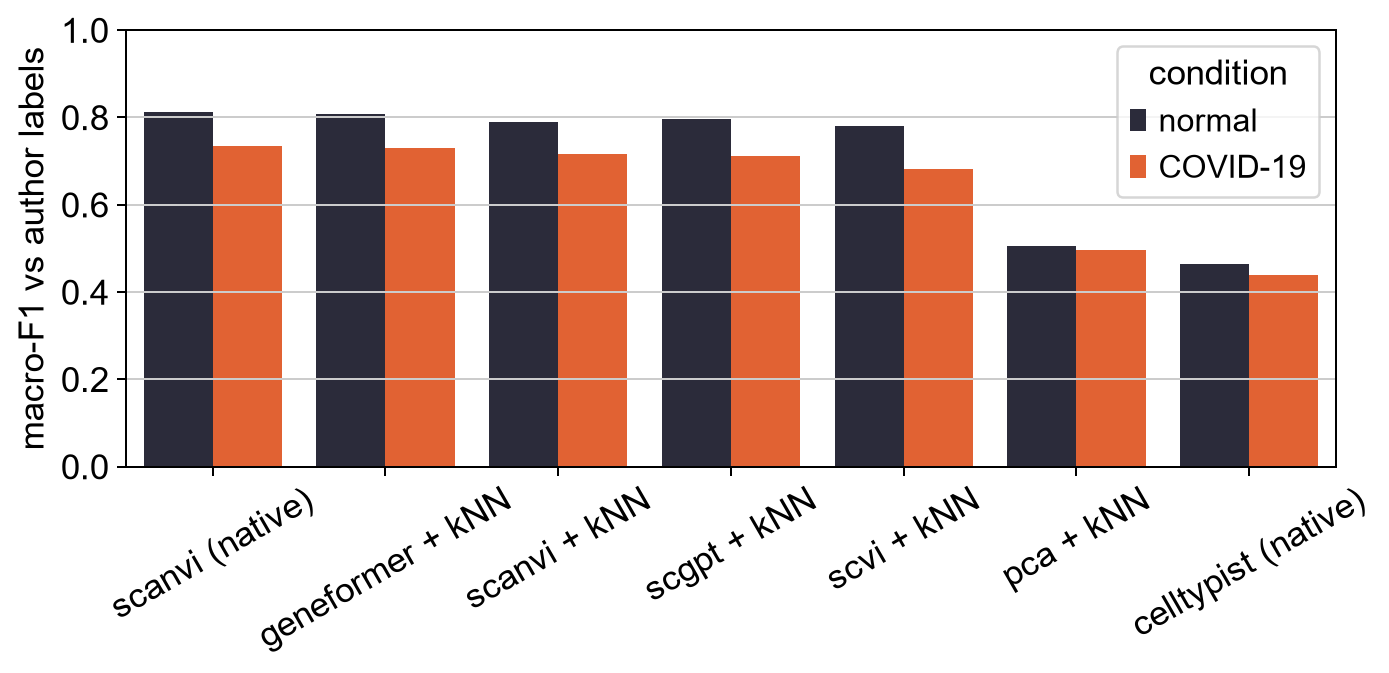

In [4]:
order = table.sort_values("COVID-19", ascending=False).index
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(scores, x="method", y="macro_f1", hue="condition", order=order, palette=COND, ax=ax)
ax.set(xlabel="", ylabel="macro-F1 vs author labels", ylim=(0, 1)); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figures/label_transfer_f1.png", dpi=200)

Per-lineage F1 on COVID cells: where do the methods disagree?

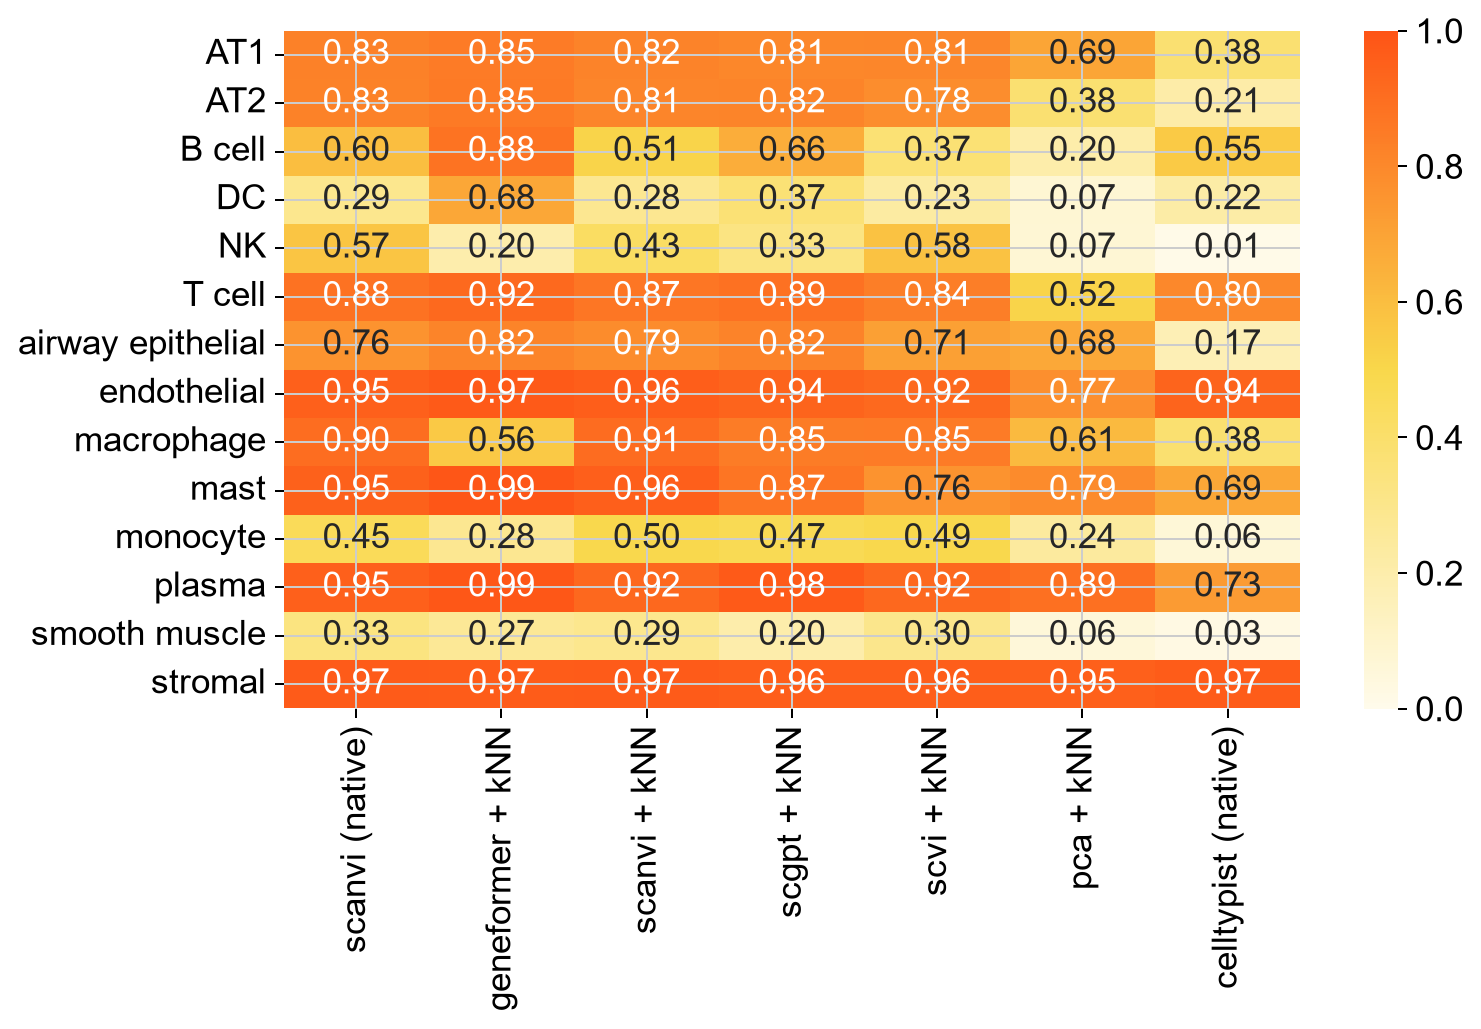

In [5]:
s = ok & (cond == "COVID-19")
labs = sorted(truth[s].unique())
per = pd.DataFrame({m: f1_score(truth[s], p.pred[s].astype(str), labels=labs, average=None) for m, p in preds.items()}, index=labs)
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(per[order], annot=True, fmt=".2f", cmap=CMAP, vmin=0, vmax=1, ax=ax)
plt.tight_layout(); plt.savefig("figures/per_lineage_f1_covid.png", dpi=200)

## 3. Integration quality (scib-metrics)
Joint reference + query embedding, stratified subsample of 30k cells. Batch = HLCA study or `Melms_2021`.

Computing neighbors:   0%|          | 0/5 [00:00<?, ?it/s]

Computing neighbors:  20%|██        | 1/5 [00:19<01:16, 19.05s/it]

Computing neighbors:  40%|████      | 2/5 [00:21<00:27,  9.17s/it]

Computing neighbors:  60%|██████    | 3/5 [00:23<00:12,  6.06s/it]

Computing neighbors:  80%|████████  | 4/5 [00:27<00:05,  5.33s/it]

Computing neighbors: 100%|██████████| 5/5 [00:31<00:00,  4.83s/it]

... (100 outputs left out)

Metrics:  80%|████████  | 8/10 [06:49<00:37, 18.89s/it, Batch correction: pcr_comparison]    

Metrics:  90%|█████████ | 9/10 [06:50<00:13, 13.38s/it, Batch correction: pcr_comparison]

Embeddings: 100%|██████████| 5/5 [20:44<00:00, 336.10s/it]

Embeddings: 100%|██████████| 5/5 [20:44<00:00, 248.82s/it]

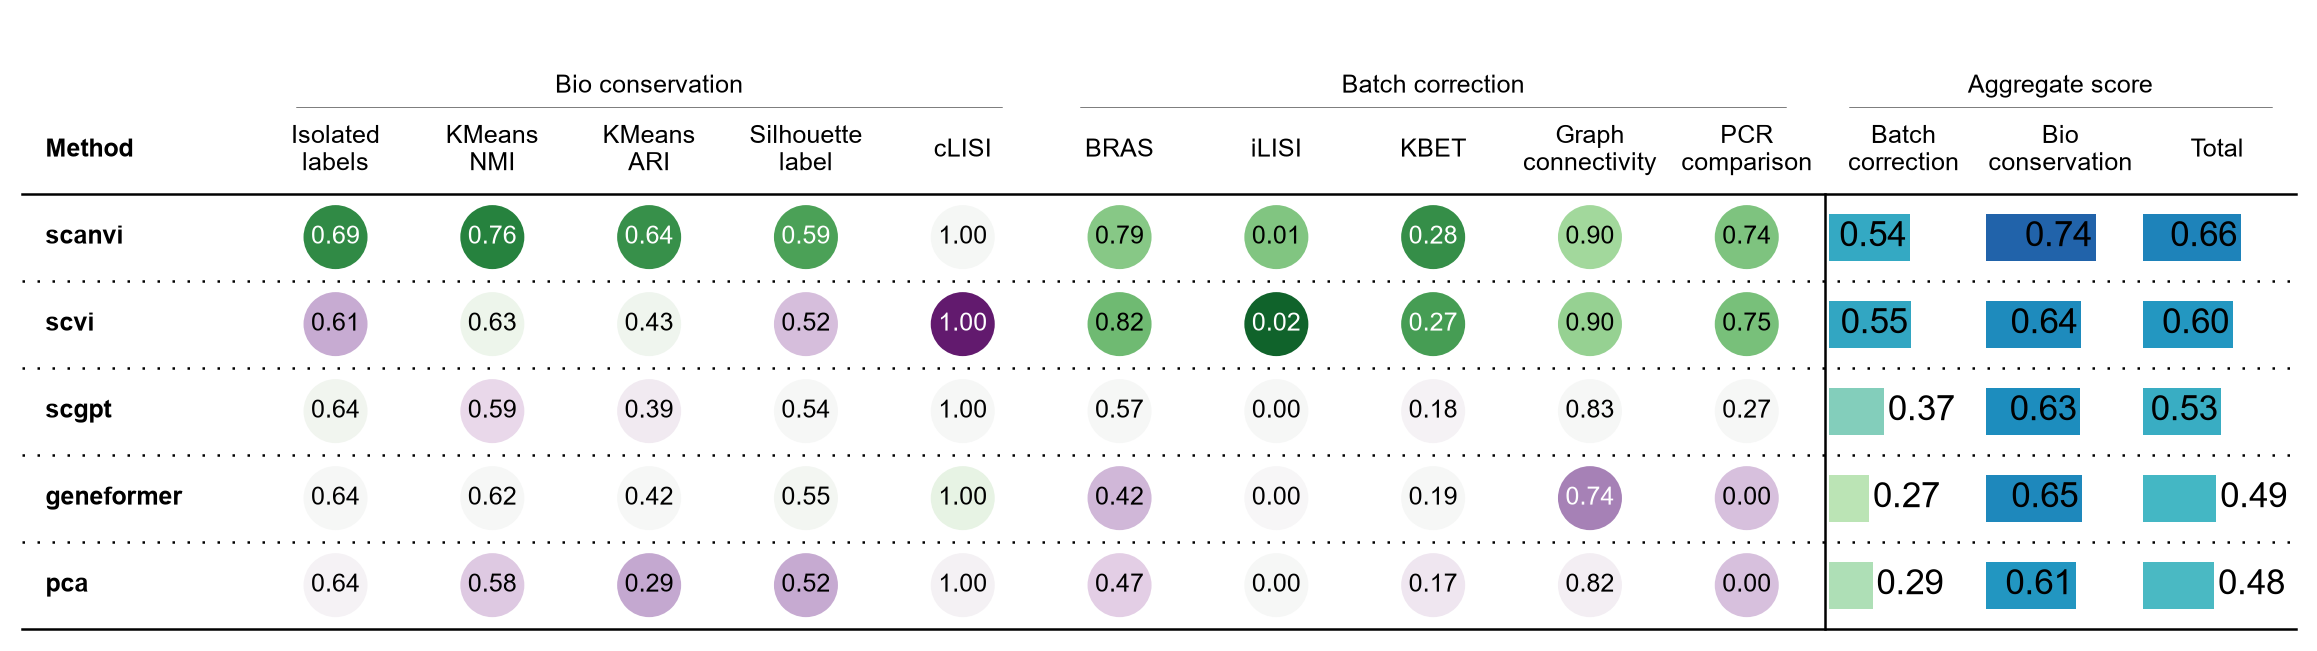

,Isolated labels,KMeans NMI,KMeans ARI,Silhouette label,cLISI,BRAS,iLISI,KBET,Graph connectivity,PCR comparison,Batch correction,Bio conservation,Total
Embedding,,,,,,,,,,,,,
pca,0.638469,0.577909,0.293274,0.51812,0.99962,0.471826,0.0,0.17203,0.821429,0.0,0.293057,0.605478,0.48051
scvi,0.612956,0.633567,0.431555,0.524164,0.997456,0.815092,0.015759,0.274013,0.904158,0.753071,0.552419,0.63994,0.604931
scanvi,0.694748,0.759193,0.637973,0.590673,0.999724,0.78811,0.008828,0.281402,0.899372,0.737825,0.543108,0.736462,0.65912
geneformer,0.640373,0.622228,0.416038,0.546698,0.999969,0.42333,0.0,0.18506,0.741064,0,0.269891,0.645061,0.494993
scgpt,0.643352,0.591256,0.391781,0.544841,0.999703,0.570576,0.0,0.181737,0.830388,0.266027,0.369746,0.634187,0.52841
Metric Type,Bio conservation,Bio conservation,Bio conservation,Bio conservation,Bio conservation,Batch correction,Batch correction,Batch correction,Batch correction,Batch correction,Aggregate score,Aggregate score,Aggregate score


In [6]:
from scib_metrics.benchmark import Benchmarker, BioConservation, BatchCorrection

lab = np.r_[y, truth.values]
batch = np.r_[ref.obs.dataset.astype(str).values, ["Melms_2021"] * nq]
keep = np.flatnonzero(lab != "unmapped")
keep = train_test_split(keep, train_size=30000, stratify=lab[keep], random_state=0)[0] if len(keep) > 30000 else keep
joint = ad.AnnData(obs=pd.DataFrame({"label": lab[keep], "batch": batch[keep]}, index=keep.astype(str)))
for m, e in emb.items():
    joint.obsm[m] = e[keep]
bm = Benchmarker(joint, batch_key="batch", label_key="label", embedding_obsm_keys=list(emb),
                 pre_integrated_embedding_obsm_key="pca", bio_conservation_metrics=BioConservation(),
                 batch_correction_metrics=BatchCorrection(), n_jobs=-1)
bm.benchmark()
bm.plot_results_table(min_max_scale=False, save_dir="figures")
bm.get_results(min_max_scale=False)

## 4. Uncertainty: are diseased cells mapped with less confidence?

condition,COVID-19,normal
pca + kNN,0.267,0.333
scvi + kNN,0.067,0.000
scanvi + kNN,0.000,0.000
geneformer + kNN,0.000,0.000
scgpt + kNN,0.000,0.000
scanvi (native),0.000,0.000
celltypist (native),1.000,1.000


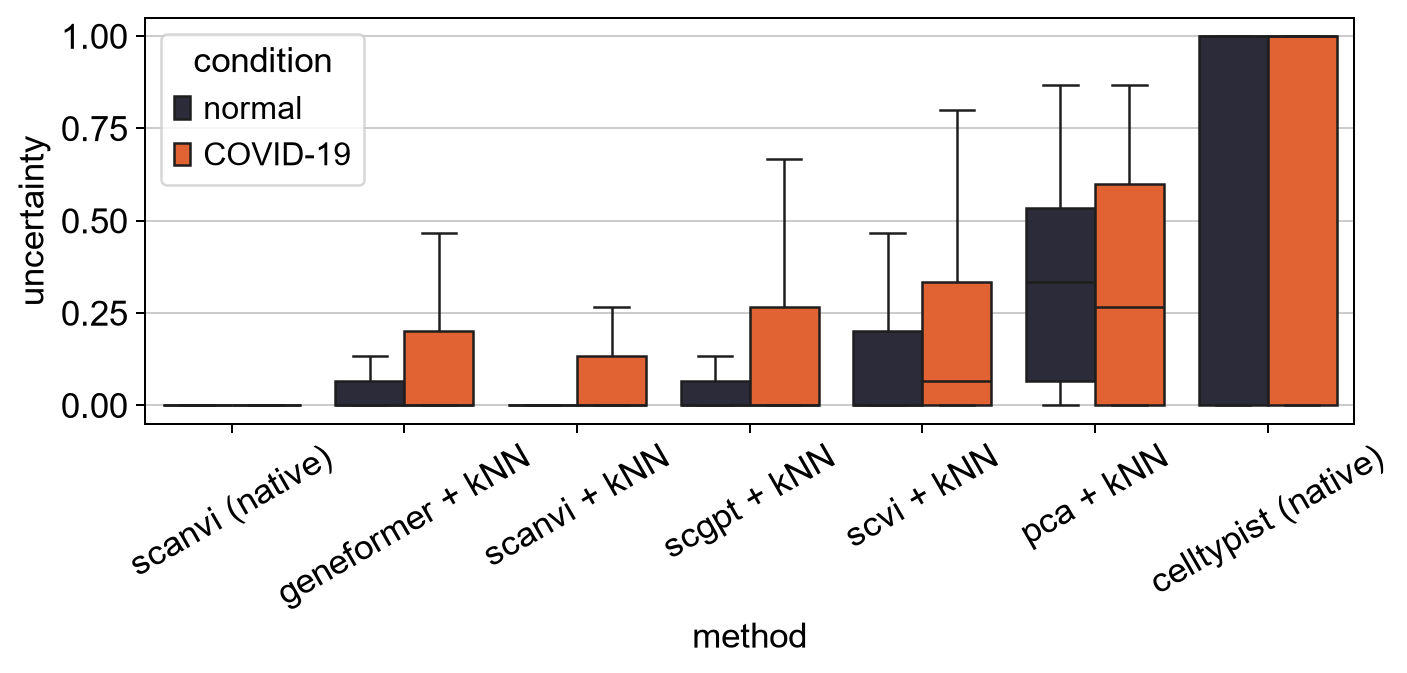

In [7]:
unc = pd.DataFrame({m: 1 - p.conf for m, p in preds.items()})
unc["condition"] = cond.values
long = unc.melt(id_vars="condition", var_name="method", value_name="uncertainty")
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(long, x="method", y="uncertainty", hue="condition", palette=COND, showfliers=False, order=order, ax=ax)
ax.tick_params(axis="x", rotation=30); plt.tight_layout(); plt.savefig("figures/uncertainty.png", dpi=200)
unc.groupby("condition").median().T.round(3)

## 5. Disease-specific cell states
Leiden clusters on the scANVI query latent. For each cluster, compare each donor's fraction of cells in it, COVID
vs control (Mann-Whitney), and report mean mapping uncertainty. COVID-enriched clusters with high uncertainty
are candidate states missing from the healthy reference.

In [8]:
qry.obsm["X_scanvi"] = emb["scanvi"][nr:]
sc.pp.neighbors(qry, use_rep="X_scanvi"); sc.tl.umap(qry); sc.tl.leiden(qry, resolution=1, flavor="igraph", n_iterations=2)
frac = pd.crosstab(qry.obs.donor_id, qry.obs.leiden, normalize="index")
dcond = qry.obs.groupby("donor_id", observed=True).disease.first().astype(str).reindex(frac.index)
cl = pd.DataFrame({
    "lineage": qry.obs.groupby("leiden", observed=True).coarse.agg(lambda x: x.value_counts().index[0]),
    "n_cells": qry.obs.leiden.value_counts(),
    "log2FC_covid": np.log2((frac[dcond == "COVID-19"].mean() + 1e-4) / (frac[dcond == "normal"].mean() + 1e-4)),
    "p": [mannwhitneyu(frac.loc[dcond == "COVID-19", c], frac.loc[dcond == "normal", c]).pvalue for c in frac],
    "uncertainty": unc.groupby(qry.obs.leiden.values)["scanvi (native)"].mean(),
})
cl.sort_values("log2FC_covid", ascending=False).round(3).head(12)

AppData\Local\Temp\ipykernel_22996\3069086178.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "uncertainty": unc.groupby(qry.obs.leiden.values)["scanvi (native)"].mean(),


,lineage,n_cells,log2FC_covid,p,uncertainty
20,stromal,69,3.649,0.012,0.013
14,unmapped,150,3.236,0.088,0.133
15,stromal,9681,2.266,0.002,0.002
6,unmapped,2466,1.710,0.063,0.083
4,macrophage,11701,1.624,0.000,0.063
3,macrophage,12689,1.416,0.004,0.004
9,unmapped,1961,1.322,0.001,0.008
13,plasma,5445,1.249,0.081,0.015
1,airway epithelial,5695,0.978,0.198,0.072
5,macrophage,5433,0.510,0.219,0.007


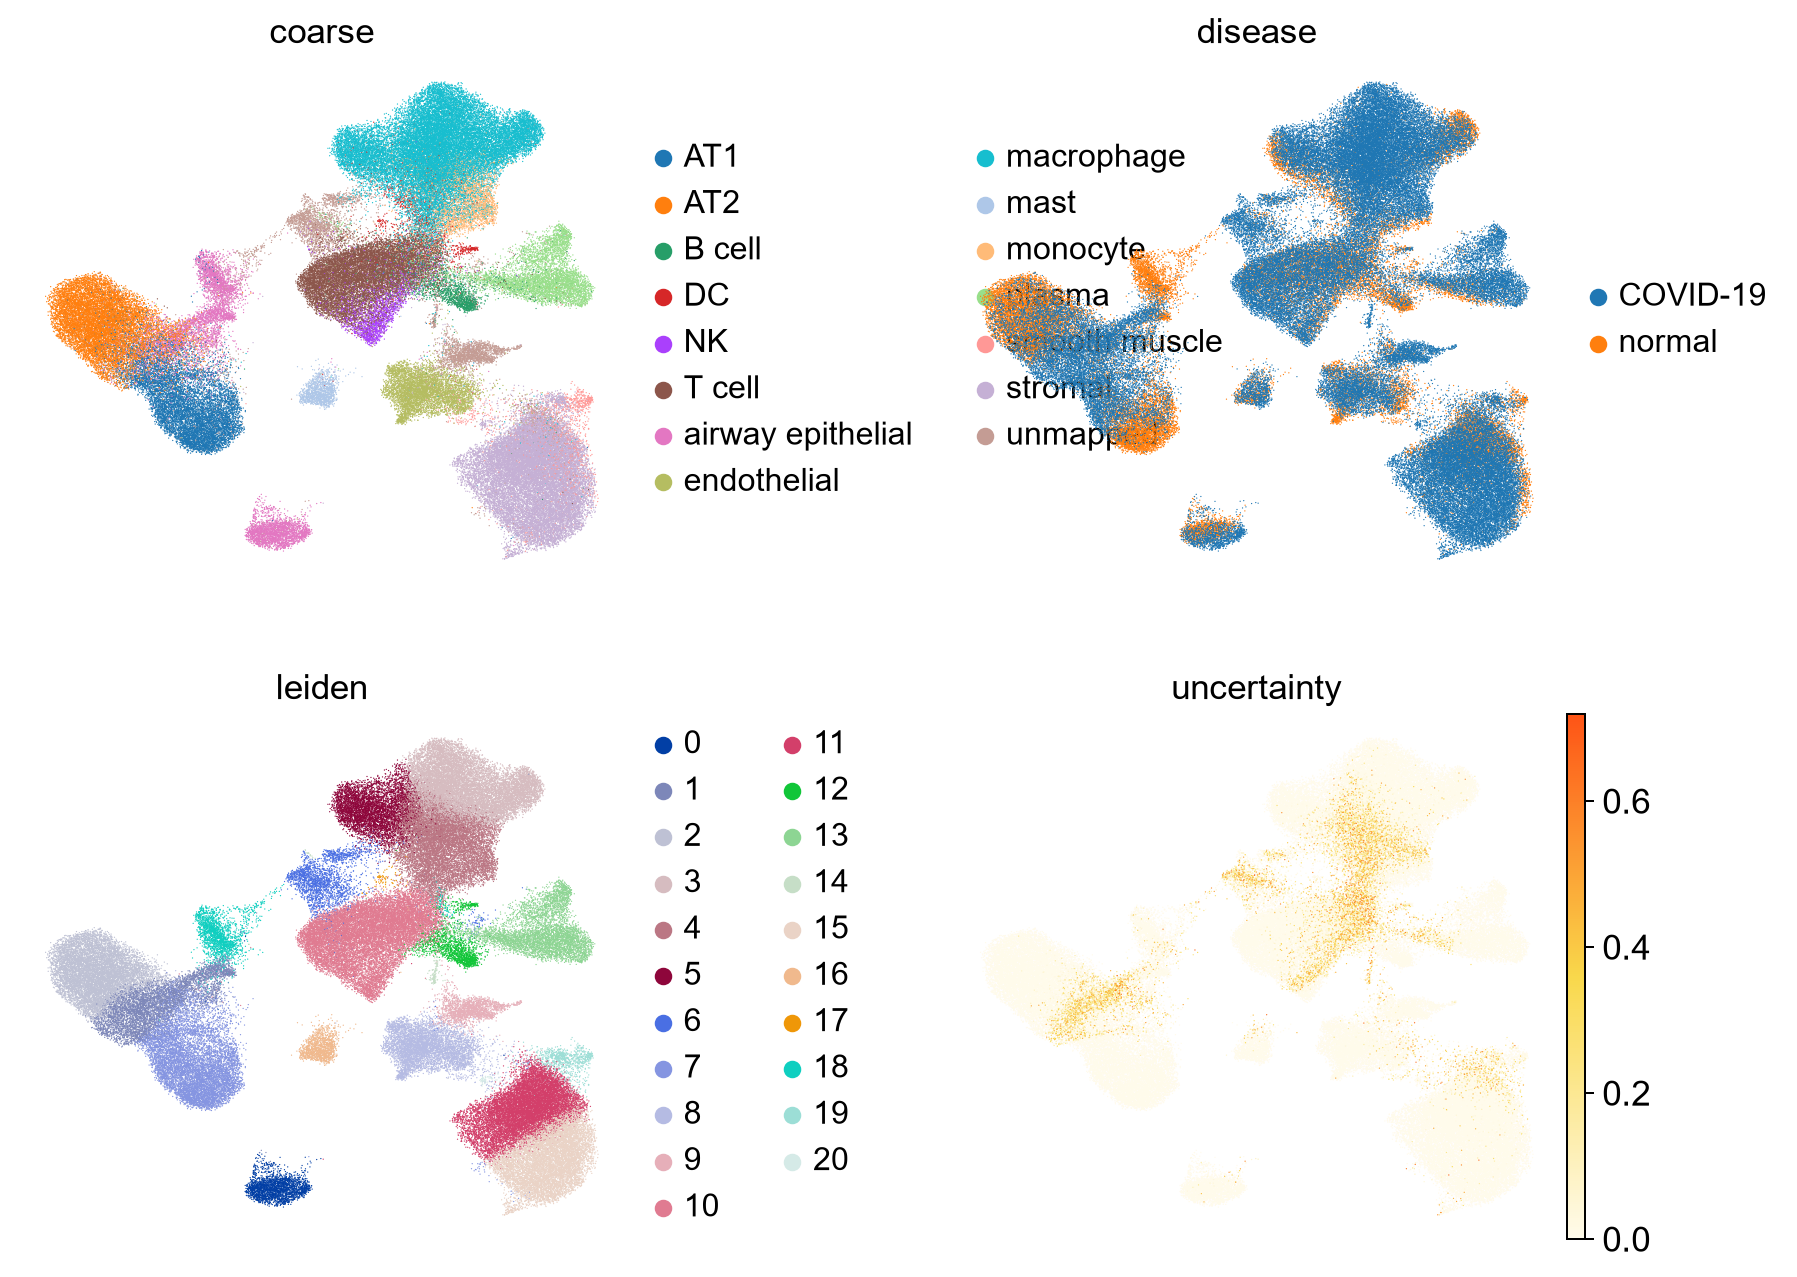

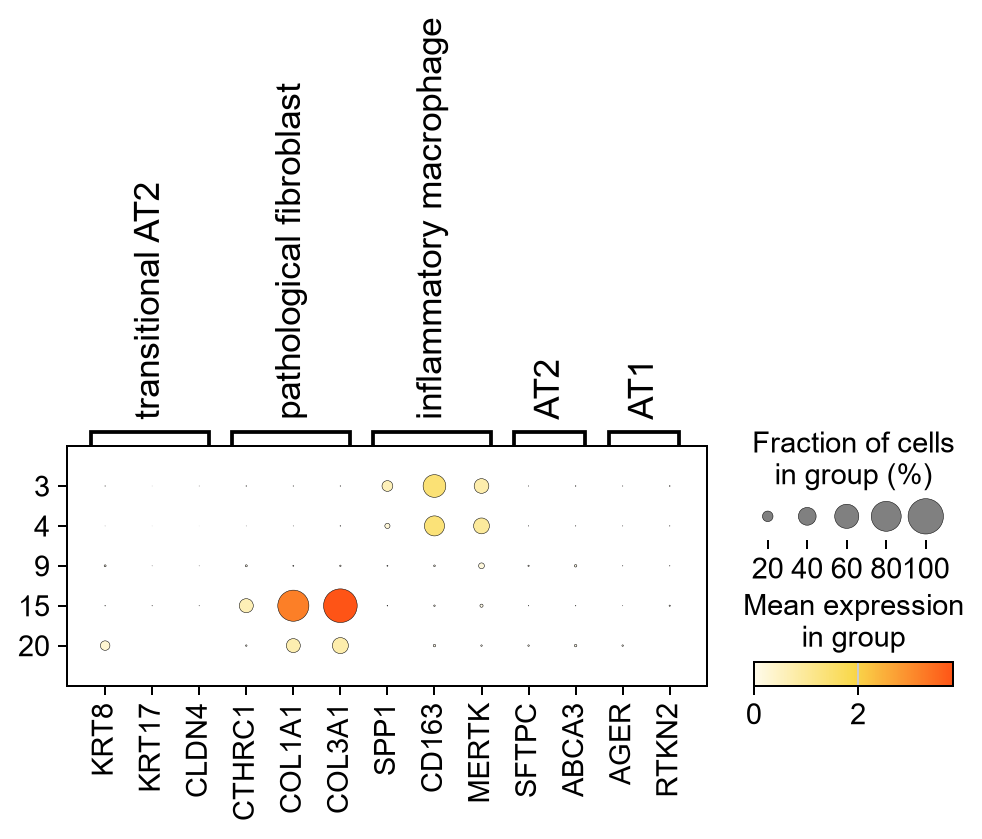

In [9]:
qry.obs["uncertainty"] = unc["scanvi (native)"].values
sc.pl.umap(qry, color=["coarse", "disease", "leiden", "uncertainty"], ncols=2, wspace=0.4,
           palette=None, cmap=CMAP, save="_query_states.png")
markers = {"transitional AT2": ["KRT8", "KRT17", "CLDN4"], "pathological fibroblast": ["CTHRC1", "COL1A1", "COL3A1"],
           "inflammatory macrophage": ["SPP1", "CD163", "MERTK"], "AT2": ["SFTPC", "ABCA3"], "AT1": ["AGER", "RTKN2"]}
top = cl[(cl.p < 0.05) & (cl.log2FC_covid > 0)].sort_values("log2FC_covid", ascending=False).index[:8].tolist()
sc.pl.dotplot(qry[qry.obs.leiden.isin(top)], markers, groupby="leiden", cmap=CMAP, save="_covid_clusters.png")

## 6. CFTR and ionocytes
Ionocytes carry most airway CFTR, but they live in airway epithelium. The query is parenchymal snRNA-seq, so expect
few or none. Check CFTR by lineage in both datasets, then what each method calls "ionocyte" in the query.

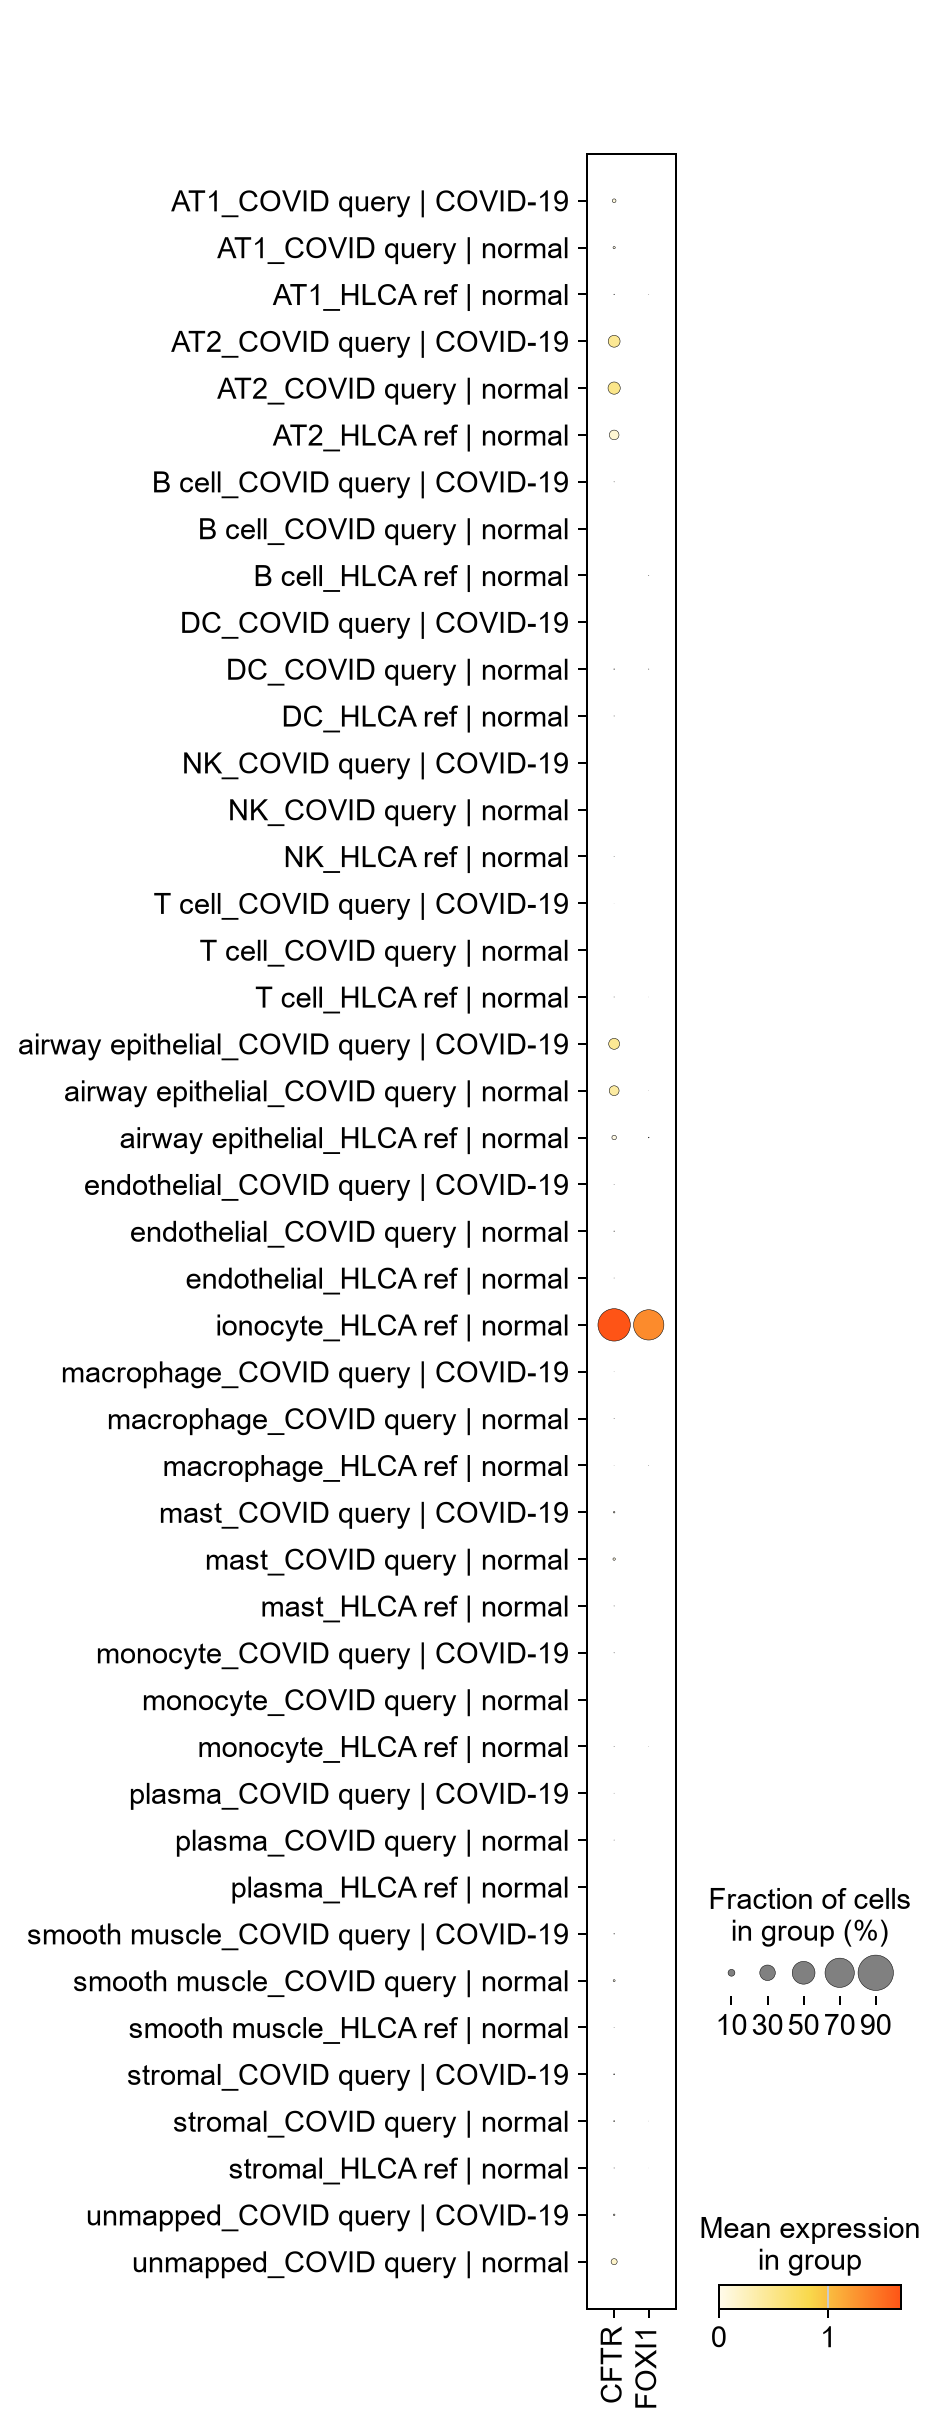

query cells labelled ionocyte by authors: 0


pca + kNN                4
scvi + kNN               8
scanvi + kNN             8
geneformer + kNN        17
scgpt + kNN            822
scanvi (native)         19
celltypist (native)      3
Name: predicted ionocytes, dtype: int64

In [10]:
both = ad.concat({"HLCA ref": ref[:, ["CFTR", "FOXI1"]], "COVID query": qry[:, ["CFTR", "FOXI1"]]}, label="source", index_unique="-")
both.obs["group"] = both.obs.source.astype(str) + " | " + np.r_[np.full(nr, "normal"), cond.values]
sc.pl.dotplot(both, ["CFTR", "FOXI1"], groupby=["coarse", "group"], cmap=CMAP, save="_cftr.png")
print("query cells labelled ionocyte by authors:", (truth == "ionocyte").sum())
pd.Series({m: (p.pred == "ionocyte").sum() for m, p in preds.items()}, name="predicted ionocytes")

## 7. Pseudobulk differential expression (COVID vs control)
Labels from the best method on COVID cells. Raw counts summed per donor × lineage; pydeseq2 with `~ disease`
per lineage (needs ≥3 donors per arm with ≥10 cells).

In [11]:
import decoupler as dc
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

best = table["COVID-19"].idxmax(); print("labels from:", best)
qry.obs["label"] = preds[best].pred.values
pb = dc.pp.pseudobulk(qry, sample_col="donor_id", groups_col="label", layer="counts", mode="sum")
pb = pb[pb.obs.psbulk_cells >= 10].copy()

res = {}
for lin in ["AT2", "AT1", "stromal", "macrophage", "endothelial", "T cell"]:
    a = pb[pb.obs.label == lin].copy()
    a.obs["disease"] = a.obs.disease.astype(str).str.replace("-", "")  # 'COVID19' / 'normal'
    if a.obs.disease.value_counts().min() < 3:
        continue
    X = a.X.toarray() if hasattr(a.X, "toarray") else np.asarray(a.X)
    counts = pd.DataFrame(X, index=a.obs_names, columns=a.var_names).astype(int)
    counts = counts.loc[:, (counts > 0).sum() >= 3]
    if counts.shape[1] < 100:  # too sparse to test (only happens on the smoke-test subset)
        continue
    dds = DeseqDataSet(counts=counts,
                       metadata=a.obs[["disease"]], design="~disease", quiet=True)
    dds.deseq2()
    st = DeseqStats(dds, contrast=["disease", "COVID19", "normal"], quiet=True); st.summary()
    res[lin] = st.results_df.dropna().sort_values("padj")
pd.DataFrame({l: [(r.padj < 0.05).sum(), ", ".join(r.index[:8])] for l, r in res.items()}, index=["n DE (padj<0.05)", "top genes"]).T

labels from: scanvi (native)


,n DE (padj<0.05),top genes
AT2,4538,"RPS17, PTMA, NACA, B2M, CEACAM6, RPL28, KCNK6,..."
AT1,3054,"CYP4Z1, RPS19, RPS28, SCD, RPL37A, RPL8, RPS27..."
stromal,3320,"IQCN, H2AC6, SLC22A23, HSPA8, FOSB, HSPE1, ZNF..."
macrophage,2921,"ENSG00000257176, ACVR1, ENSG00000234961, SHISA..."
endothelial,1337,"CRACDL, HSPB1, ENSG00000249207, HSP90AA1, RASA..."
T cell,856,"HSPA8, NEAT1, HSP90AB1, HSP90AA1, HSPE1, JUND,..."


,log2FoldChange,padj
AT2,-0.612,0.283
AT1,0.442,0.676
stromal,-0.669,0.584
macrophage,NaN,NaN
endothelial,-0.656,0.728
T cell,NaN,NaN


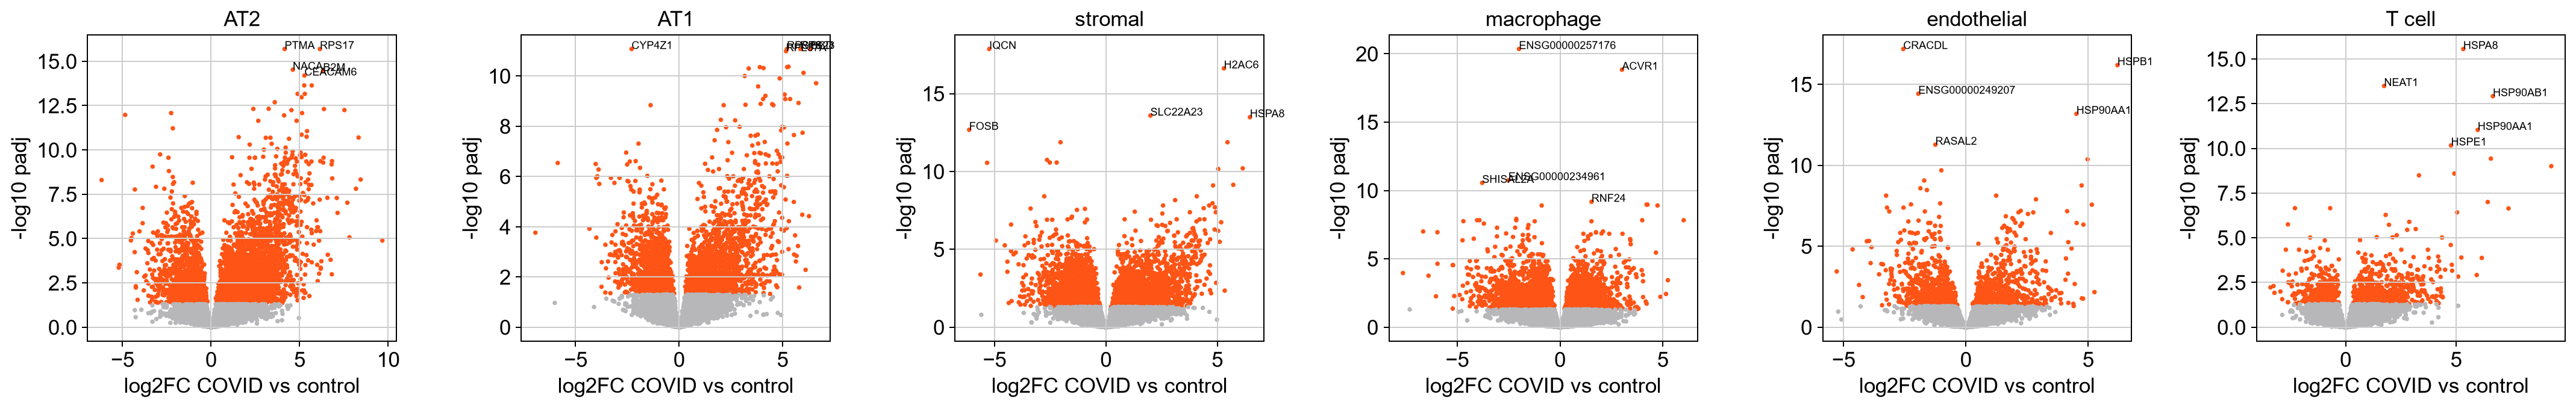

In [12]:
fig, axes = plt.subplots(1, len(res), figsize=(4 * len(res), 4), sharey=False)
for ax, (lin, r) in zip(np.atleast_1d(axes), res.items()):
    sig = r.padj < 0.05
    ax.scatter(r.log2FoldChange, -np.log10(r.padj), s=4, c=np.where(sig, TANGERINE, DOVE))
    for g in r.index[:5]:
        ax.annotate(g, (r.log2FoldChange[g], -np.log10(r.padj[g])), fontsize=7)
    ax.set(title=lin, xlabel="log2FC COVID vs control", ylabel="-log10 padj")
plt.tight_layout(); plt.savefig("figures/pseudobulk_volcanos.png", dpi=200)
pd.DataFrame({l: r.loc["CFTR", ["log2FoldChange", "padj"]] if "CFTR" in r.index else pd.Series(dtype=float) for l, r in res.items()}).T.round(3)